# Exploratory Data Analysis

Data: `data/processed/results_hybrid_2026_drivers.csv` from `02_preprocessing`. It covers 2014–2024 and the 18 drivers on the 2026 grid who raced before 2025. One row is one driver in one race.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

PROCESSED = Path("../data/processed")
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROCESSED / "results_hybrid_2026_drivers.csv", parse_dates=["date"])

# Chart styling: one accent hue, neutral ink for text, recessive grid
ACCENT = "#2a78d6"
MUTED = "#c3c2b7"
INK = "#0b0b0b"
INK_2 = "#52514e"
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "text.color": INK,
})

## 1. Dataset overview

In [2]:
print(f"Rows: {len(df):,}  |  Races: {df.raceId.nunique()}  |  Drivers: {df.driverId.nunique()}  |  Seasons: {df.year.min()}–{df.year.max()}")
print(f"Podium rate: {df.podium.mean():.1%}  ({df.podium.sum()} podiums, {(df.podium == 0).sum()} non-podiums)")

# Only current drivers are kept, so some races have fewer than 3 podium rows
podiums_per_race = df.groupby("raceId").podium.sum()
print("\nPodium finishers per race that are in this dataset:")
print(podiums_per_race.value_counts().sort_index().rename("races").to_string())

Rows: 2,514  |  Races: 228  |  Drivers: 18  |  Seasons: 2014–2024
Podium rate: 20.2%  (509 podiums, 2005 non-podiums)

Podium finishers per race that are in this dataset:
podium
0      6
1     51
2     55
3    116


## 2. Podium rate by starting grid position

How much does the starting position decide the result? A grid value of 0 means the driver started from the pit lane.

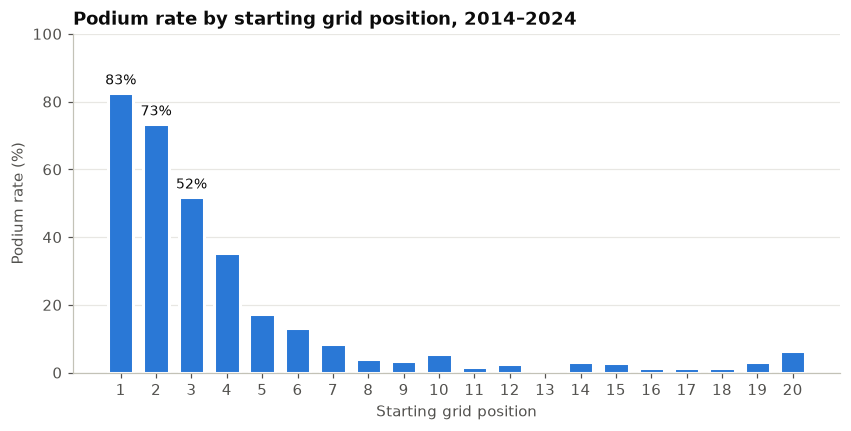

,podium_rate_%,starts
grid,,
1,82.6,184
2,73.5,162
3,51.9,160
4,35.3,156
5,17.3,156
6,13.2,144
7,8.3,168
8,4.1,148
9,3.3,152


In [3]:
grid = df[df.grid > 0].groupby("grid").agg(rate=("podium", "mean"), starts=("podium", "size"))
grid = grid[grid.index <= 20]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(grid.index, grid.rate * 100, width=0.72, color=ACCENT, edgecolor="white", linewidth=2)
for pos in (1, 2, 3):
    ax.text(pos, grid.rate[pos] * 100 + 1.5, f"{grid.rate[pos]:.0%}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(grid.index)
ax.set_xlabel("Starting grid position")
ax.set_ylabel("Podium rate (%)")
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)
ax.set_title("Podium rate by starting grid position, 2014–2024")
fig.savefig(FIGURES / "eda_podium_rate_by_grid.png")
plt.show()

grid.assign(rate=lambda t: (t.rate * 100).round(1)).rename(columns={"rate": "podium_rate_%"}).head(10)

## 3. Podium rate by qualifying position

Qualifying usually sets the grid, but grid penalties can move a driver back. Comparing the two shows how much information each one carries.

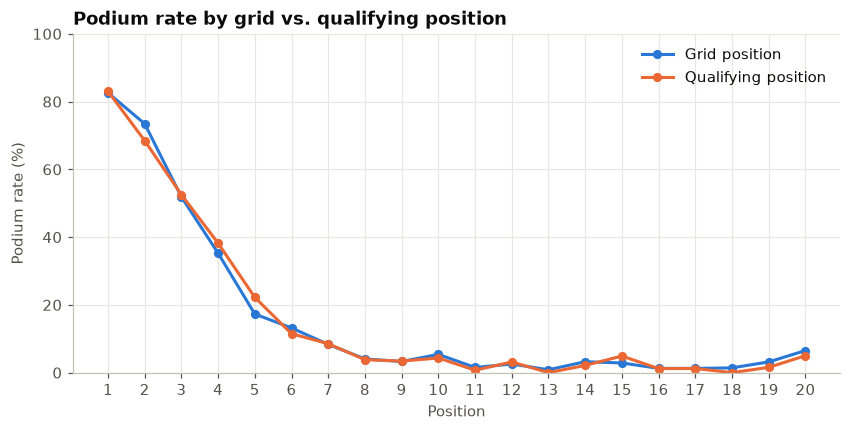

Grid differs from qualifying in 26.7% of starts (penalties, pit-lane starts, other drivers' penalties)


In [4]:
quali = df.dropna(subset=["quali_position"]).groupby("quali_position").podium.mean()
quali = quali[quali.index <= 20]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(grid.index, grid.rate * 100, color=ACCENT, linewidth=2, marker="o", markersize=5, label="Grid position")
ax.plot(quali.index, quali * 100, color="#eb6834", linewidth=2, marker="o", markersize=5, label="Qualifying position")
ax.set_xticks(range(1, 21))
ax.set_xlabel("Position")
ax.set_ylabel("Podium rate (%)")
ax.set_ylim(0, 100)
ax.legend(frameon=False)
ax.set_title("Podium rate by grid vs. qualifying position")
fig.savefig(FIGURES / "eda_grid_vs_quali.png")
plt.show()

gap = df[(df.grid > 0) & df.quali_position.notna()]
print(f"Grid differs from qualifying in {(gap.grid != gap.quali_position).mean():.1%} of starts (penalties, pit-lane starts, other drivers' penalties)")

## 4. Podiums by team and season

Team strength changes a lot from year to year, which is why recent team form should be a feature. Teams appear under the names they had at the time (for example, Force India later became Racing Point and then Aston Martin).

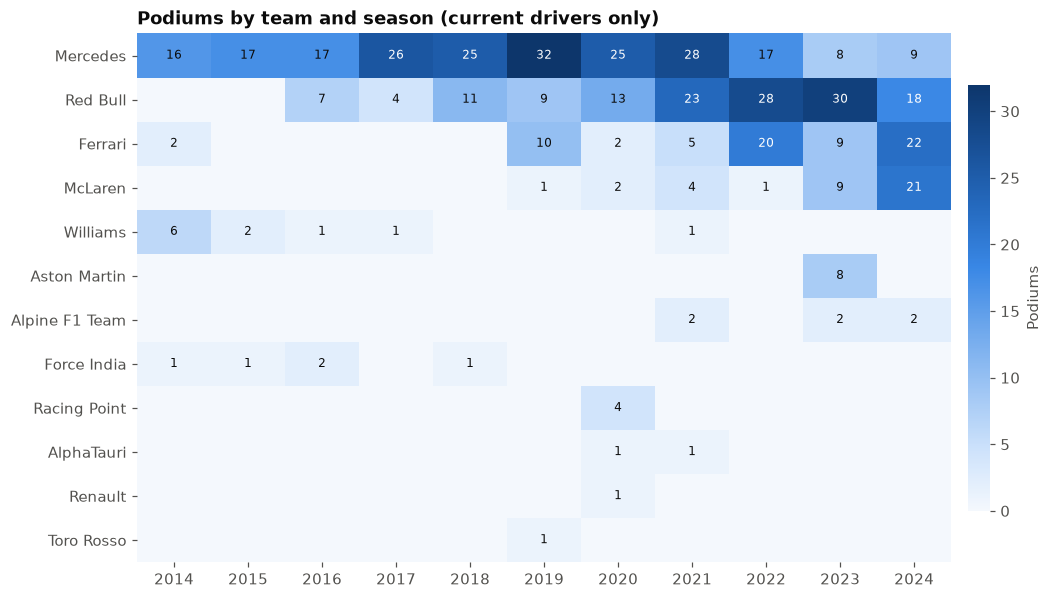

In [5]:
team_season = df.pivot_table(index="constructor", columns="year", values="podium", aggfunc="sum", fill_value=0)
team_season = team_season.loc[team_season.sum(axis=1).sort_values(ascending=False).index]
team_season = team_season[team_season.sum(axis=1) > 0]

fig, ax = plt.subplots(figsize=(10, 0.42 * len(team_season) + 1.2))
im = ax.imshow(team_season.values, cmap=SEQ_BLUE, aspect="auto")
ax.set_xticks(range(team_season.shape[1]), team_season.columns)
ax.set_yticks(range(team_season.shape[0]), team_season.index)
ax.grid(False)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
vmax = team_season.values.max()
for i in range(team_season.shape[0]):
    for j in range(team_season.shape[1]):
        v = team_season.iat[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > vmax * 0.55 else INK)
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("Podiums", color=INK_2)
cbar.outline.set_visible(False)
ax.set_title("Podiums by team and season (current drivers only)")
fig.savefig(FIGURES / "eda_team_season_podiums.png")
plt.show()

## 5. Drivers

Podium counts are very uneven between drivers. Some of the current drivers have only a handful of starts.

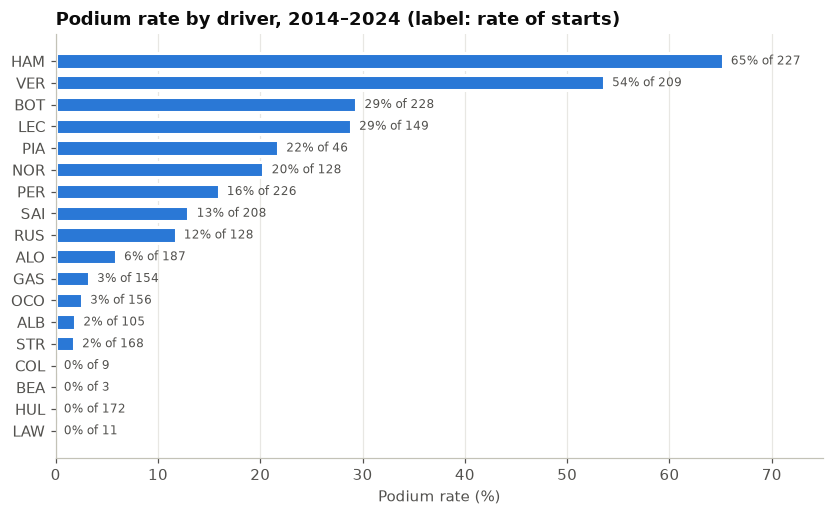

,starts,podiums,podium_rate,finish_rate,first_season
code,,,,,
HAM,227,148,65.2,93.8,2014
VER,209,112,53.6,84.7,2015
BOT,228,67,29.4,87.7,2014
LEC,149,43,28.9,83.9,2018
PIA,46,10,21.7,93.5,2023
NOR,128,26,20.3,91.4,2019
PER,226,36,15.9,87.6,2014
SAI,208,27,13.0,80.8,2015
RUS,128,15,11.7,84.4,2019


In [6]:
finished = df.status.eq("Finished") | df.status.str.startswith("+", na=False)
drivers = (
    df.assign(finished=finished)
    .groupby("code")
    .agg(starts=("raceId", "size"), podiums=("podium", "sum"), podium_rate=("podium", "mean"),
         finish_rate=("finished", "mean"), first_season=("year", "min"))
    .sort_values("podium_rate", ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(drivers))
ax.barh(y, drivers.podium_rate * 100, height=0.7, color=ACCENT, edgecolor="white", linewidth=2)
for yi, (rate, n) in enumerate(zip(drivers.podium_rate, drivers.starts)):
    ax.text(rate * 100 + 0.8, yi, f"{rate:.0%} of {n}", va="center", fontsize=8, color=INK_2)
ax.set_yticks(y, drivers.index)
ax.invert_yaxis()
ax.set_xlabel("Podium rate (%)")
ax.set_xlim(0, 75)
ax.grid(axis="y", visible=False)
ax.set_title("Podium rate by driver, 2014–2024 (label: rate of starts)")
fig.savefig(FIGURES / "eda_driver_podium_rate.png")
plt.show()

drivers.assign(podium_rate=lambda t: (t.podium_rate * 100).round(1), finish_rate=lambda t: (t.finish_rate * 100).round(1))

## 6. Podium rate over the seasons

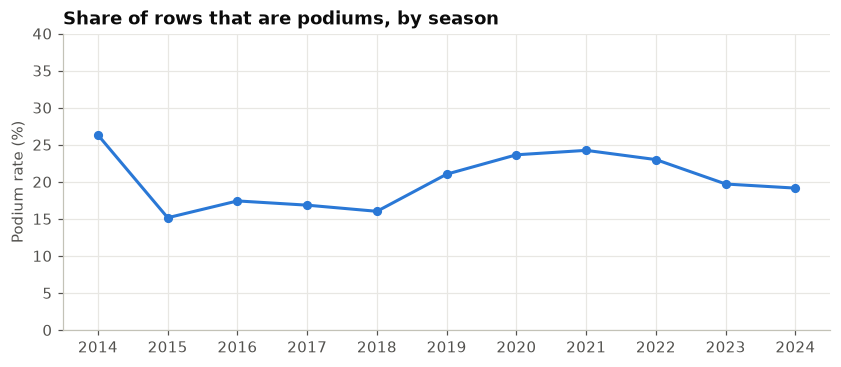

In [7]:
season = df.groupby("year").podium.mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(season.index, season.values, color=ACCENT, linewidth=2, marker="o", markersize=5)
ax.set_xticks(season.index)
ax.set_ylabel("Podium rate (%)")
ax.set_ylim(0, max(40, season.max() + 5))
ax.set_title("Share of rows that are podiums, by season")
fig.savefig(FIGURES / "eda_podium_rate_by_season.png")
plt.show()

## 7. A simple baseline: "starts in the top 3 means a podium"

The random forest has to beat this rule. Plain accuracy would be misleading, because predicting "no podium" every time is already about 80% accurate.

In [8]:
pred = (df.grid.between(1, 3)).astype(int)
tp = ((pred == 1) & (df.podium == 1)).sum()
fp = ((pred == 1) & (df.podium == 0)).sum()
fn = ((pred == 0) & (df.podium == 1)).sum()
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)
accuracy = (pred == df.podium).mean()

print(f"Always predict 'no podium': accuracy {1 - df.podium.mean():.1%}, recall 0%")
print(f"Grid top-3 rule: accuracy {accuracy:.1%}, precision {precision:.1%}, recall {recall:.1%}, F1 {f1:.3f}")

Always predict 'no podium': accuracy 79.8%, recall 0%
Grid top-3 rule: accuracy 87.8%, precision 70.0%, recall 69.5%, F1 0.698


## Key takeaways

1. **Starting position matters most.** Starting P1 gives an 83% podium rate, P2 73%, P3 52% and P4 35%. From P5 down it falls below 20%, and from P8 down it's under 6%.
2. **The simple baseline is strong.** The rule "a top-3 start means a podium" gets 87.8% accuracy, 70.0% precision, 69.5% recall and an F1 of 0.698. The random forest's job is to beat this F1, mainly by catching the roughly 30% of podiums that start outside the top 3.
3. **Accuracy is the wrong measure.** Predicting "no podium" every time is already 79.8% accurate, because only 20.2% of rows are podiums. Report precision, recall and F1, or PR-AUC.
4. **Qualifying and grid position are close but not the same.** They differ in 26.7% of starts because of penalties. Grid is the slightly stronger signal for P2, and qualifying for P4–P5. Keep both as features.
5. **Team strength changes between eras.** Mercedes dominated 2014–2021, Red Bull took over in 2021–2023, and McLaren and Ferrari rose in 2024. A rolling recent-team-form feature should help more than a fixed team label.
6. **Driver history is uneven.** Hamilton (227 starts) and Verstappen (209) account for about half of all podiums. Bearman (3), Colapinto (9) and Lawson (11) have almost no history, and four 2026 drivers have none at all. Features should fall back on team form when a driver has little history.
7. **A side effect of the driver filter:** only 116 of 228 races include all 3 podium finishers in this dataset, because the others went to drivers not on the 2026 grid. Season podium rates (15–26%) partly reflect who was racing then, not only how competitive the season was.
